# Lab 3 — Deep Q-Network (DQN) on CartPole-v1

In this lab we implement **DQN** (Mnih et al., 2015) from scratch with PyTorch and train it on the classic control task **CartPole-v1** from Gymnasium.

- **State** $s \in \mathbb{R}^4$: cart position, cart velocity, pole angle, pole angular velocity.
- **Actions** $a \in \{0, 1\}$: push the cart to the left or to the right.
- **Reward**: $+1$ for every step the pole stays upright. An episode ends when the pole falls or the cart leaves the track (*terminated*), or after 500 steps (*truncated*).
- **Solved**: average return $\geq 475$ over 100 consecutive episodes.



> ###  Exercise version
> Complete the code marked **`TODO 1` … `TODO 6`**. 
>
> | TODO | Where | What you write |
> |---|---|---|
> | 1 | §4 `QNetwork` | layers and forward pass |
> | 2 | §6 `DQNAgent.act` | ε-greedy action |
> | 3 | §6 `compute_targets` | $y = r + \gamma(1-\text{terminated})\max_{a'}Q(s',a';\theta^-)$ |
> | 4 | §6 `learn` | $Q(s_i,a_i;\theta)$, MSE loss |
> | 5| §6 `update_target_network` | hard copy $\theta^-\leftarrow\theta$ every $C$ steps |
> | 6 | §8 `train` | one interaction step|



## 1. Imports


In [5]:
import random
import time
from collections import deque, namedtuple

import gymnasium as gym
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from tqdm import tqdm


## 2. Device

Use the GPU when one is available, otherwise the CPU. Every tensor and network will be moved to `device`.


In [6]:
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")


Check the library versions and the selected device.


In [7]:
print(f"gymnasium {gym.__version__} | torch {torch.__version__} | device: {device}")


gymnasium 1.4.0 | torch 2.11.0+cu130 | device: cuda:0


## 3. Reproducibility

Reinforcement learning results vary a lot from one run to another. To make experiments reproducible, we seed every random number generator we use: Python (`random`, used for ε-greedy and replay sampling), NumPy and PyTorch (network initialisation).


In [8]:
def set_seed(seed: int) -> None:
    """Seed every random number generator we use (Python, NumPy, PyTorch)."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


## 4. The Q-network

DQN approximates the action-value function with a neural network $Q(s, a; \theta)$.
Instead of taking $(s, a)$ as input, the network takes only the state $s$ and outputs **one Q-value per action**, so a single forward pass gives $Q(s, \cdot\,; \theta)$ and the greedy action is simply the `argmax` of the output.

Architecture: `state_dim → 64 → 64 → action_dim` with ReLU activations. The last layer is **linear**, because a Q-value can be any real number.


In [9]:
class QNetwork(nn.Module):

    def __init__(self, state_dim: int, action_dim: int, hidden_dim: int = 64):
        super().__init__()
        # TODO 1 (a) — three fully connected layers: fc1 (state_dim -> hidden_dim), fc2 (hidden_dim -> hidden_dim)
        #              and out (hidden_dim -> action_
        self.fc1 = nn.Linear(state_dim, hidden_dim)
        self.fc2 = nn.Linear(hidden_dim, hidden_dim)
        self.out = nn.Linear(hidden_dim, action_dim)

    def forward(self, state: torch.Tensor) -> torch.Tensor:
        # TODO 1 (b) — ReLU after fc1 and fc2; NO activation on the output (a Q-value can be any real number)
        # 
        x = F.relu(self.fc1(state))
        x = F.relu(self.fc2(x))
        return self.out(x)  


## 5. Experience replay

Consecutive transitions are strongly correlated, which breaks the i.i.d. assumption of stochastic gradient descent.
DQN stores every transition $(s, a, r, s', \text{terminated})$ in a **replay memory** $\mathcal{D}$ (a FIFO buffer of fixed capacity) and learns from **random minibatches** sampled uniformly from it. This:

- decorrelates the samples of a minibatch,
- reuses each transition many times (better data efficiency).

`sample()` returns the minibatch already converted into tensors on `device`.


In [10]:
Transition = namedtuple("Transition", ("state", "action", "reward", "next_state", "terminated"))


class ReplayMemory:
    

    def __init__(self, capacity: int):
        self.memory = deque(maxlen=capacity)  # the oldest transitions are dropped automatically

    def push(self, state, action, reward, next_state, terminated):
        self.memory.append(Transition(state, action, reward, next_state, terminated))

    def sample(self, batch_size: int):
        
        batch = random.sample(self.memory, batch_size) 
        states, actions, rewards, next_states, terminateds = zip(*batch)  
        return (
            torch.as_tensor(np.array(states), dtype=torch.float32, device=device),
            torch.as_tensor(actions, dtype=torch.int64, device=device),
            torch.as_tensor(rewards, dtype=torch.float32, device=device),
            torch.as_tensor(np.array(next_states), dtype=torch.float32, device=device),
            torch.as_tensor(terminateds, dtype=torch.float32, device=device),
        )

    def __len__(self):
        return len(self.memory)


## 6. The DQN agent

The agent combines the two key ideas of DQN:

1. **Experience replay** (the memory $\mathcal{D}$ above).
2. **Target network** $\theta^-$: a copy of the online network used to compute the targets, so that the targets do not move at every gradient step.

For a minibatch, the **target** is
$$y_i = r_i + \gamma \,(1 - \text{terminated}_i)\,\max_{a'} Q(s'_i, a'; \theta^-)$$
and the loss is the mean squared error
$$\mathcal{L}(\theta) = \frac{1}{B}\sum_{i=1}^{B}\big(y_i - Q(s_i, a_i; \theta)\big)^2 .$$

The targets are computed under `torch.no_grad()`: they are treated as constants (**semi-gradient**).

Target network update:
- **hard**: $\theta^- \leftarrow \theta$ every $C$ gradient steps,


> **Note:** only `terminated` stops the bootstrap. When an episode is *truncated* (500 steps reached), $s'$ is not terminal and its value must still be bootstrapped.


In [20]:
class DQNAgent:
    """DQN (Mnih et al., 2015): online network θ, target network θ⁻, replay memory D."""

    def __init__(self, state_dim, action_dim, hidden_dim=64, lr=5e-4, gamma=0.99,
                 buffer_size=100_000, batch_size=64, learn_every=1, target_update_every=100, seed=0):
        set_seed(seed)
        self.action_dim = action_dim
        self.gamma = gamma
        self.batch_size = batch_size
        self.learn_every = learn_every                  # one gradient step every `learn_every` env steps
        self.target_update_every = target_update_every  # C, counted in gradient steps
       

        self.q_net = QNetwork(state_dim, action_dim, hidden_dim).to(device)       
        self.target_net = QNetwork(state_dim, action_dim, hidden_dim).to(device)  
        self.target_net.load_state_dict(self.q_net.state_dict())                 

        self.optimizer = optim.Adam(self.q_net.parameters(), lr=lr)  # optimises θ only
        self.memory = ReplayMemory(buffer_size)
        self.env_steps = 0  # environment steps seen
        self.updates = 0    # gradient steps done
        self.losses = []

    def act(self, state, epsilon=0.0):
        
        if random.random() < epsilon:
            # TODO 2 — ε-greedy: with probability epsilon a uniformly random action (random.randrange); 
            return random.randrange(self.action_dim)
        with torch.no_grad():                                                 
            state_t = torch.as_tensor(state, dtype=torch.float32, device=device).unsqueeze(0) 
            # TODO 2 — ε-greedy:  the greedy action argmax_a Q(s, a; θ), computed under torch.no_grad()
            return int(self.q_net(state_t).argmax(dim=1).item())

    def step(self, state, action, reward, next_state, terminated):
        """Store the transition; every `learn_every` steps, learn from a random minibatch."""
        self.memory.push(state, action, reward, next_state, terminated)
        self.env_steps += 1
        if self.env_steps % self.learn_every == 0 and len(self.memory) >= self.batch_size:
            self.learn(self.memory.sample(self.batch_size))


    def compute_targets(self, rewards, next_states, terminateds):
        """y = r + γ (1 − terminated) max_a' Q(s', a'; θ⁻) """
        # TODO 3 — max over the actions of the TARGET network, then the target y (shape (B,))  
        
        next_q_values = self.target_net(next_states)
        max_next_q_values = next_q_values.max(dim=1).values
        return rewards + self.gamma * (1 - terminateds) * max_next_q_values

    def learn(self, batch):
        states, actions, rewards, next_states, terminateds = batch

        # 1) targets: constants for the optimiser (semi-gradient) -> no graph is recorded
        with torch.no_grad():
            targets = self.compute_targets(rewards, next_states, terminateds)  

        # 2) predictions Q(s_i, a_i; θ) for the actions that were actually taken
        q_values = self.q_net(states)                               
        q_sa = q_values.gather(1, actions.unsqueeze(1)).squeeze(1) 

        # 3) loss and one gradient step on θ
        # TODO 4-  MSE loss between q_sa and targets; append loss.item() to self.losses;
        loss = torch.nn.functional.mse_loss(q_sa, targets)
        
        self.losses.append(loss.item())

        self.optimizer.zero_grad()
        loss.backward()
        self.optimizer.step()

        # 4) target network
        self.updates += 1
        self.update_target_network()
        

    def update_target_network(self):
        """Hard: θ⁻ ← θ every C gradient steps"""
        if self.updates % self.target_update_every == 0:
               # TODO 5 — copy the weights of q_net into target_net when self.updates is a multiple of target_update_every
            self.target_net.load_state_dict(self.q_net.state_dict())
       


## 7. Exploration schedule

The agent acts with an **ε-greedy** policy: a random action with probability ε, the greedy action $\arg\max_a Q(s, a; \theta)$ otherwise.
ε decreases **linearly** from `eps_start` (pure exploration) to `eps_end` over `decay_steps` environment steps, then stays constant.


In [21]:

def epsilon_at(step: int, eps_start: float = 1.0, eps_end: float = 0.05, decay_steps: int = 10_000) -> float:
    """Linear ε schedule: eps_start at step 0, eps_end after `decay_steps` environment steps, then constant."""
    fraction = min(1.0, step / decay_steps)
    return eps_start + fraction * (eps_end - eps_start)


## 8. Training loop

For every episode:
1. reset the environment (a different but reproducible seed per episode),
2. at every step: choose an ε-greedy action, apply it, store the transition and (possibly) do one gradient step,
3. record the episode return.

Training stops early when the 100-episode moving average reaches `target_score`.


In [22]:
def train(agent, env, n_episodes=300, eps_start=1.0, eps_end=0.05, eps_decay_steps=10_000,
          seed=0, target_score=None, verbose=True):

    """Train `agent` on `env` and return the list of episode returns."""

    scores, window = [], deque(maxlen=100)
    progress = tqdm(range(1, n_episodes + 1), disable=not verbose)

    for episode in progress:
        state, _ = env.reset(seed=seed * 10_000 + episode)  # reproducible, different start states
        score, done = 0.0, False
        while not done:
            
            eps = epsilon_at(agent.env_steps, eps_start, eps_end, eps_decay_steps)

            # TODO 6 — one interaction step:
            #    (1) ε-greedy action, ,
            #    (2) env.step(action)
            #    (3) agent.step(...) storing `terminated` (NOT done)
            action = agent.act(state, epsilon=eps)
            next_state, reward, terminated, truncated, _ = env.step(action)
            agent.step(state, action, reward, next_state, terminated)
            
           
            done = terminated or truncated                             
            state = next_state
            score += reward

        scores.append(score)
        window.append(score)
        progress.set_postfix(avg100=f"{np.mean(window):.1f}", eps=f"{eps:.2f}")
        
        # stop as soon as the task is solved
        if target_score is not None and len(window) == 100 and np.mean(window) >= target_score:
            print(f"Solved in {episode} episodes: average return {np.mean(window):.1f} over the last 100")
            break
    return scores


## 9. Train the agent

Train DQN on CartPole-v1 with the default hyperparameters (hard target update every 100 gradient steps, linear ε decay over 10 000 steps), then save the trained online network $\theta$ to `dqn_cartpole.pth`.


In [23]:
env = gym.make("CartPole-v1")
agent = DQNAgent(state_dim=env.observation_space.shape[0], action_dim=env.action_space.n, seed=0)

start = time.time()
scores = train(agent, env, n_episodes=500, target_score=475, seed=0)  # stop as soon as the task is solved
print(f"{len(scores)} episodes | {agent.env_steps} environment steps | {agent.updates} gradient steps | "
      f"{time.time() - start:.0f} s")
torch.save(agent.q_net.state_dict(), "dqn_cartpole.pth")


  1%|          | 4/500 [00:00<00:14, 33.75it/s, avg100=27.9, eps=0.98]

100%|██████████| 500/500 [06:17<00:00,  1.32it/s, avg100=394.4, eps=0.05]

500 episodes | 137455 environment steps | 137392 gradient steps | 378 s


## 10. Learning curves

- **Left**: return of each episode and its 100-episode moving average. The dashed line is the "solved" threshold (475).
- **Right**: moving average of the training loss (log scale).

> Unlike in supervised learning, the DQN loss does **not** necessarily decrease: the targets change as the network improves. The return curve is the real measure of progress.


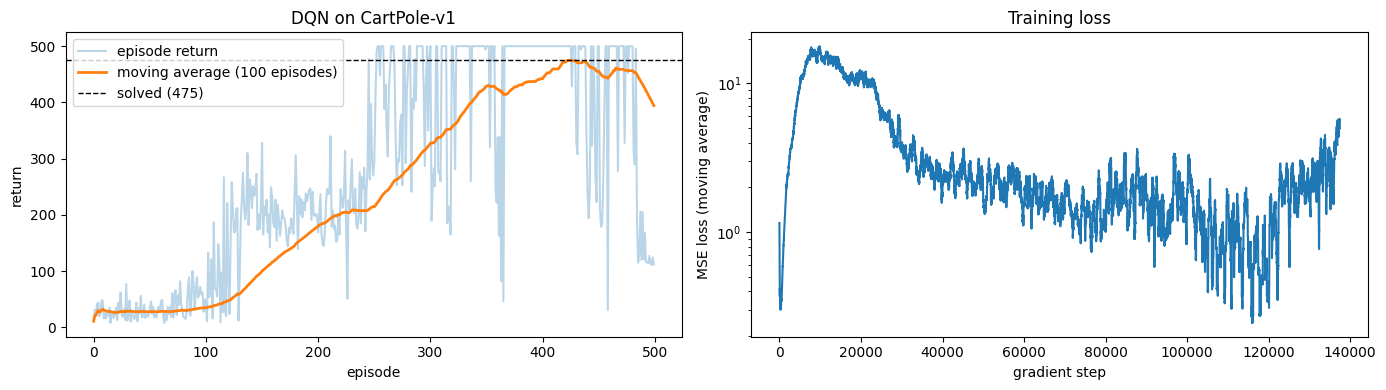

,episode return
count,500.0
mean,274.9
std,183.6
min,8.0
25%,114.0
50%,240.0
75%,500.0
max,500.0


In [24]:
# Episode returns and their moving average (the usual way to read an RL learning curve)
window, threshold = 100, 475
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
s = pd.Series(scores)
axes[0].plot(s, alpha=0.3, label="episode return")
axes[0].plot(s.rolling(window, min_periods=1).mean(), lw=2, label=f"moving average ({window} episodes)")
axes[0].axhline(threshold, ls="--", c="k", lw=1, label=f"solved ({threshold})")
axes[0].set(xlabel="episode", ylabel="return", title="DQN on CartPole-v1")
axes[0].legend(loc="upper left")

axes[1].plot(pd.Series(agent.losses).rolling(500, min_periods=1).mean())
axes[1].set(xlabel="gradient step", ylabel="MSE loss (moving average)", yscale="log", title="Training loss")
plt.tight_layout()
plt.show()
pd.Series(scores, name="episode return").describe().round(1)


## 11. Evaluation of the saved model

We reload `dqn_cartpole.pth` into a fresh agent and evaluate the **greedy policy** (ε = 0) on 100 new episodes, with seeds that were never used during training.

We report:
- the mean ± standard deviation, min and max of the returns,
- the fraction of episodes that reach the maximum return (500),
- whether the task is solved (mean return $\geq 475$),
- a **strip plot** of the returns on the full range $[0, 500]$: each dot is one episode, the shaded band contains the middle 50% of the episodes, the black bar is the median and the white diamond is the mean.


Saved model: 110.2 ± 2.9 over 100 episodes | min 105, max 117 | 0% episodes reach 500 | solved (mean ≥ 475): False


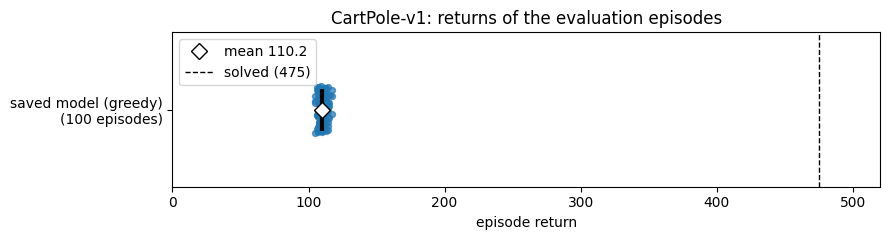

In [25]:
def evaluate(agent, env, n_episodes=100, seed=100_000):
    """Greedy policy (ε = 0) on `n_episodes` fresh episodes (seeds never used in training).
    Returns the array of (undiscounted) episode returns."""
    agent.q_net.eval()
    returns = np.zeros(n_episodes)
    for i in range(n_episodes):
        state, _ = env.reset(seed=seed + i)
        done = False
        while not done:
            state, reward, terminated, truncated, _ = env.step(agent.act(state, epsilon=0.0))
            returns[i] += reward
            done = terminated or truncated
    return returns


eval_env = gym.make("CartPole-v1")

# 1) load the saved network into a fresh agent
saved_agent = DQNAgent(state_dim=eval_env.observation_space.shape[0], action_dim=eval_env.action_space.n)
saved_agent.q_net.load_state_dict(torch.load("dqn_cartpole.pth", map_location=device, weights_only=True))

# 2) greedy evaluation
returns = evaluate(saved_agent, eval_env)
print(f"Saved model: {returns.mean():.1f} ± {returns.std():.1f} over {len(returns)} episodes | "
      f"min {returns.min():.0f}, max {returns.max():.0f} | "
      f"{(returns == 500).mean():.0%} episodes reach 500 | solved (mean ≥ 475): {returns.mean() >= 475}")



# 3) strip plot of the greedy returns on the full range [0, 500]: one dot per episode
#    shaded band = 25%–75% of the episodes, black bar = median, white diamond = mean
rng = np.random.default_rng(0)  # small vertical jitter, only so that the dots do not overlap
q1, median, q3 = np.percentile(returns, [25, 50, 75])
fig, ax = plt.subplots(figsize=(9, 2.5))
ax.hlines(0, q1, q3, lw=22, color="C0", alpha=0.25)
ax.scatter(returns, rng.uniform(-0.15, 0.15, len(returns)), s=18, color="C0", alpha=0.7)
ax.plot(median, 0, "|", ms=30, mew=3, c="k")
ax.plot(returns.mean(), 0, "D", ms=8, mfc="white", mec="k", label=f"mean {returns.mean():.1f}")
ax.axvline(475, c="k", ls="--", lw=1, label="solved (475)")
ax.set_yticks([0], [f"saved model (greedy)\n({len(returns)} episodes)"])
ax.set(xlim=(0, 520), ylim=(-0.5, 0.5), xlabel="episode return",
       title="CartPole-v1: returns of the evaluation episodes")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()
eval_env.close()


## 12. Watch the saved agent vs a random agent

We reload `dqn_cartpole.pth` and compare it with a **random agent** (uniform random actions) on the **same start states** (same seeds):

1. both agents play 5 episodes: return, length, and whether the episode ended by failure (*terminated*) or by reaching the 500-step limit (*truncated*);
2. one episode of each is rendered with `render_mode="rgb_array"` (each frame is returned as an RGB image, no window is opened) and shown **side by side in the same video**: random agent on the left, DQN agent on the right. When an agent fails, its last frame stays frozen and is marked in red.

Rendering CartPole needs `pygame` (we install `pygame-ce`, a drop-in fork that provides the same `pygame` module and has wheels for Python 3.14), and writing an MP4 needs `imageio` + `imageio-ffmpeg`. Run the next cell once, then restart the kernel if a package was newly installed.


In [ ]:
#%pip install pygame-ce imageio imageio-ffmpeg  # pygame-ce: maintained fork of pygame with wheels for recent Python versions


In [26]:
import imageio
from IPython.display import Image, Video, display
from PIL import Image as PILImage, ImageDraw, ImageFont

video_env = gym.make("CartPole-v1", render_mode="rgb_array")

# 1) the two agents: the saved DQN (greedy) and a random agent
video_agent = DQNAgent(state_dim=video_env.observation_space.shape[0], action_dim=video_env.action_space.n)
video_agent.q_net.load_state_dict(torch.load("dqn_cartpole.pth", map_location=device, weights_only=True))
video_agent.q_net.eval()
video_env.action_space.seed(0)  # reproducible random actions
policies = {"Random agent": lambda s: video_env.action_space.sample(),
            "DQN agent": lambda s: video_agent.act(s, epsilon=0.0)}


def play(policy, seed, render=False):
    """One episode; returns (return, number of steps, terminated, frames)."""
    state, _ = video_env.reset(seed=seed)
    frames, episode_return, done = [video_env.render()] if render else [], 0.0, False
    while not done:
        state, reward, terminated, truncated, _ = video_env.step(policy(state))
        if render:
            frames.append(video_env.render())
        episode_return += reward
        done = terminated or truncated
    return episode_return, int(episode_return), terminated, frames  # reward = +1 per step


# 2) same 5 start states for both agents (seeds never used in training or evaluation)
for name, policy in policies.items():
    for i in range(5):
        ret, steps, terminated, _ = play(policy, seed=200_000 + i)
        print(f"{name:12s} | episode {i}: return {ret:5.0f} | {steps:3d} steps | "
              f"{'failure (terminated)' if terminated else 'success: 500-step limit reached (truncated)'}")
    print()

# 3) one episode of each, from the same start state, side by side in the same video
font = ImageFont.load_default(size=22)
episodes = {name: play(policy, seed=200_000, render=True) for name, policy in policies.items()}
n_frames = max(len(ep[3]) for ep in episodes.values())


def annotate(name, t, ep):
    """Write the agent name and its running return; freeze and mark the last frame once the episode is over."""
    ret, steps, terminated, frames = ep
    over = t >= len(frames) - 1
    img = PILImage.fromarray(frames[min(t, len(frames) - 1)])
    draw = ImageDraw.Draw(img)
    draw.text((10, 8), name, fill=(0, 0, 0), font=font)
    draw.text((10, 36), f"step {min(t, steps)} | return {min(t, steps)}", fill=(0, 0, 0), font=font)
    if over:
        msg, color = ("FAILED (terminated)", (200, 0, 0)) if terminated else ("500 steps: success", (0, 140, 0))
        draw.text((10, 64), msg, fill=color, font=font)
    return np.asarray(img)


separator = np.full((video_env.render().shape[0], 8, 3), 60, dtype=np.uint8)
video = [np.hstack([annotate("Random agent", t, episodes["Random agent"]), separator,
                    annotate("DQN agent", t, episodes["DQN agent"])]) for t in range(n_frames)]
video_env.close()

# 4) save as MP4 (GIF if ffmpeg is missing) and show it
fps = video_env.metadata.get("render_fps", 50)
try:
    imageio.mimsave("random_vs_dqn_cartpole.mp4", video, fps=fps, macro_block_size=1)
    display(Video("random_vs_dqn_cartpole.mp4", embed=True))
except Exception:
    imageio.mimsave("random_vs_dqn_cartpole.gif", video[::2], duration=2000 / fps, loop=0)  # every 2nd frame
    display(Image("random_vs_dqn_cartpole.gif"))
print(" | ".join(f"{name}: return {ep[0]:.0f}" for name, ep in episodes.items()))


Random agent | episode 0: return    21 |  21 steps | failure (terminated)
Random agent | episode 1: return    17 |  17 steps | failure (terminated)
Random agent | episode 2: return     8 |   8 steps | failure (terminated)
Random agent | episode 3: return    15 |  15 steps | failure (terminated)
Random agent | episode 4: return    12 |  12 steps | failure (terminated)

DQN agent    | episode 0: return   111 | 111 steps | failure (terminated)
DQN agent    | episode 1: return   108 | 108 steps | failure (terminated)
DQN agent    | episode 2: return   114 | 114 steps | failure (terminated)
DQN agent    | episode 3: return   114 | 114 steps | failure (terminated)
DQN agent    | episode 4: return   109 | 109 steps | failure (terminated)



Random agent: return 20 | DQN agent: return 111
